# 06 — Robustness Checks

**Project:** Causal ML for Climate Policy Effectiveness  
**Purpose:** Validate causal estimates through placebo tests, sensitivity analysis, LOO  
**Input:** `data/processed/analysis_panel.csv`  
**Output:** Robustness tables and placebo plots

---

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.causal_models import run_ols_baseline, run_dml
from src.robustness import (
    placebo_test_time, placebo_test_outcome,
    leave_one_out_analysis, alternative_specifications
)
from src.visualization import set_publication_style, save_figure, COLORS

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
set_publication_style()

panel = pd.read_csv(PROCESSED_DIR / "analysis_panel.csv")
print(f"Panel: {panel.shape}")

Panel: (7630, 77)


In [2]:
# Setup common variables
OUTCOME = "log_co2"
TREATMENT = [c for c in panel.columns if c.startswith("treat_")][0]  # primary treatment

potential_covariates = [
    "population", "gdp_per_capita", "urban_pct", "co2_lag1"
]
COVARIATES = [c for c in potential_covariates if c in panel.columns]

print(f"Treatment: {TREATMENT}")
print(f"Covariates: {len(COVARIATES)}")

Treatment: treat_carbon_pricing
Covariates: 4


---
## 6.1 — Placebo Test (Time)

6.1 — Temporal Placebo Test


 shift         label  estimate  ci_lower  ci_upper  std_error  n_obs
    -5 Placebo (t-5) -0.195768 -0.224091 -0.167445   0.014451   6651
    -3 Placebo (t-3) -0.190779 -0.222262 -0.159296   0.016063   6653
    -1 Placebo (t-1) -0.211216 -0.244271 -0.178161   0.016865   6655
     0        Actual -0.193926 -0.227814 -0.160039   0.017290   6655


  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\placebo_test_time.png


  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\placebo_test_time.pdf


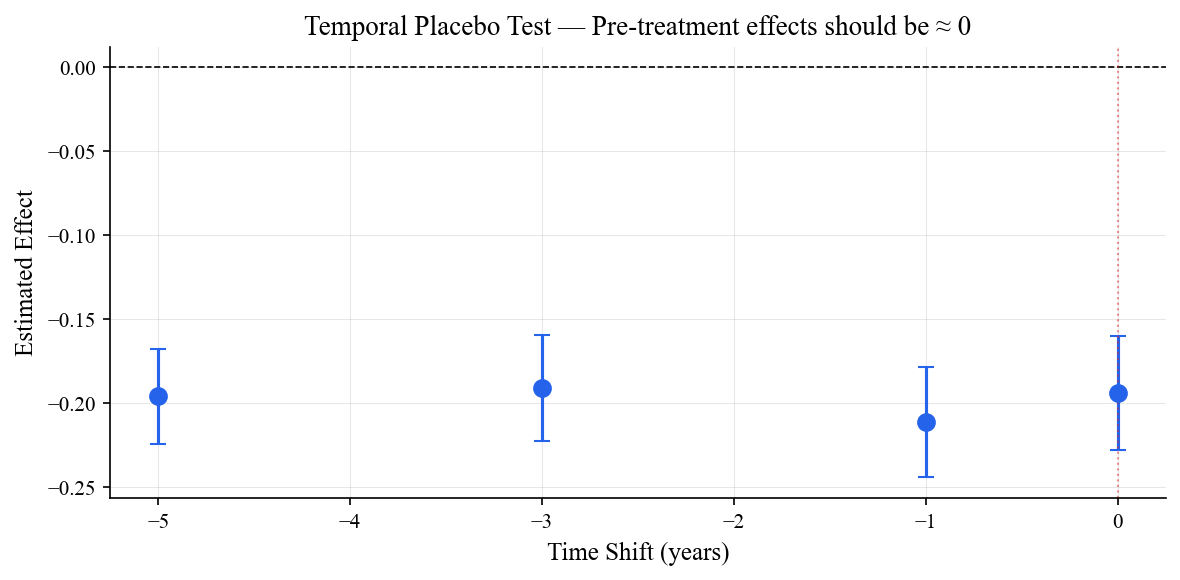

In [3]:
print("=" * 60)
print("6.1 — Temporal Placebo Test")
print("=" * 60)

placebo_time = placebo_test_time(
    panel, run_ols_baseline, TREATMENT, OUTCOME, COVARIATES,
    placebo_shifts=[-5, -3, -1, 0],
    fe_cols=["iso3", "year"]
)
print(placebo_time.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(8, 4))
valid = placebo_time.dropna(subset=["estimate"])
colors = [COLORS["primary"] if s == 0 else COLORS["neutral"] for s in valid["shift"]]
ax.errorbar(valid["shift"], valid["estimate"],
            yerr=[valid["estimate"] - valid["ci_lower"], valid["ci_upper"] - valid["estimate"]],
            fmt="o", capsize=4, color=COLORS["primary"], markersize=8)
ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.axvline(0, color=COLORS["danger"], linestyle=":", linewidth=1, alpha=0.5)
ax.set_xlabel("Time Shift (years)")
ax.set_ylabel("Estimated Effect")
ax.set_title("Temporal Placebo Test — Pre-treatment effects should be ≈ 0")
plt.tight_layout()
save_figure(fig, "placebo_test_time")
plt.show()

---
## 6.2 — Leave-One-Out Analysis

6.2 — Leave-One-Out Stability


           dropped  estimate  ci_lower  ci_upper  n_obs
None (Full Sample) -0.193926 -0.227814 -0.160039   6655
               ABW -0.193909 -0.227777 -0.160042   6621
               AFG -0.191206 -0.225087 -0.157325   6630
               AGO -0.195172 -0.229112 -0.161232   6621
               AIA -0.193926 -0.227814 -0.160039   6655
               ALB -0.194663 -0.228936 -0.160391   6621
               AND -0.194729 -0.228692 -0.160765   6621
               ARE -0.199153 -0.233595 -0.164710   6621
               ARG -0.195102 -0.229264 -0.160939   6621
               ARM -0.193193 -0.227130 -0.159256   6621
               ATA -0.193926 -0.227814 -0.160039   6655


  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\leave_one_out.png
  Saved: F:\Nexus_Projects\causal-climate-policy\outputs\figures\leave_one_out.pdf


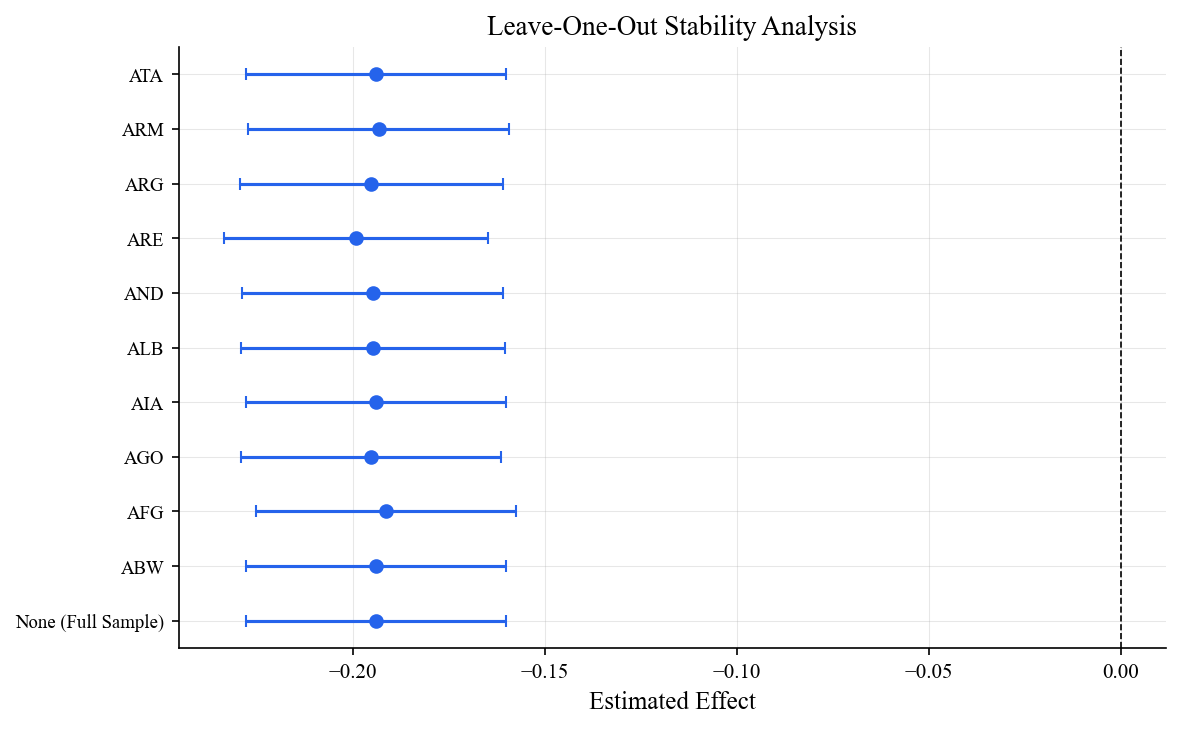

In [4]:
print("=" * 60)
print("6.2 — Leave-One-Out Stability")
print("=" * 60)

loo_results = leave_one_out_analysis(
    panel, run_ols_baseline, OUTCOME, TREATMENT, COVARIATES, top_n=10,
    fe_cols=["iso3", "year"]
)

if len(loo_results) > 0:
    print(loo_results.to_string(index=False))
    
    # Plot
    fig, ax = plt.subplots(figsize=(8, 5))
    y_pos = range(len(loo_results))
    colors = [COLORS["primary"] if d == "None (Full Sample)" else COLORS["neutral"]
              for d in loo_results["dropped"]]
    ax.errorbar(loo_results["estimate"], y_pos,
                xerr=[loo_results["estimate"] - loo_results["ci_lower"],
                      loo_results["ci_upper"] - loo_results["estimate"]],
                fmt="o", capsize=3, color=COLORS["primary"])
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels(loo_results["dropped"], fontsize=9)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Estimated Effect")
    ax.set_title("Leave-One-Out Stability Analysis")
    plt.tight_layout()
    save_figure(fig, "leave_one_out")
    plt.show()

---
## 6.3 — Alternative Specifications

In [5]:
print("=" * 60)
print("6.3 — Alternative Specifications")
print("=" * 60)

# Define different covariate sets
extended_cols = COVARIATES + ["regulatory_quality", "renewables_share_energy"]
extended_cols = [c for c in extended_cols if c in panel.columns]

specs = {
    "Minimal": [c for c in ["gdp_per_capita", "population"] if c in panel.columns],
    "Baseline": COVARIATES,
    "Extended": extended_cols,
}

# Filter out empty specs
specs = {k: v for k, v in specs.items() if len(v) > 0}

alt_results = alternative_specifications(
    panel, run_ols_baseline, OUTCOME, TREATMENT, specs,
    fe_cols=["iso3", "year"]
)

if len(alt_results) > 0:
    print(alt_results.to_string(index=False))
    alt_results.to_csv(TABLE_DIR / "alternative_specifications.csv", index=False)
    print("\n Robustness checks complete")
    print("  Proceed to Notebook 07: Results Visualization")

6.3 — Alternative Specifications


specification  n_covariates  estimate  ci_lower  ci_upper  std_error  n_obs
      Minimal             2 -0.219579 -0.255611 -0.183547   0.018384   6845
     Baseline             4 -0.193926 -0.227814 -0.160039   0.017290   6655
     Extended             6  0.104574  0.068651  0.140498   0.018329   2028

 Robustness checks complete
  Proceed to Notebook 07: Results Visualization
